In [1]:
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ["pandeia_refdata"] = os.path.abspath("raw Pandeira/pandeia_data-2026.7-jwst")
from pandeia.engine.instrument_factory import InstrumentFactory
# Vega is only used to convert source spectra to/from magnitudes during full ETC calculations. get_total_eff touches none of that — it reads instrument throughput FITS files and multiplies them. - warning can be ignored

In [2]:
OUT_DIR = "Spiderman"
# Data downloaded from https://outerspace.stsci.edu/display/PEN/Pandeia+Engine+Installation
# LRS is a disperser, not a filter, so multiple ranges can be chosen
WINDOWS = {
    "MIRI/LRS 5.0-10.5": (5.0, 10.5),   # red end trimmed (throughput falls, background climbs)
    "MIRI/LRS 5.0-12.0": (5.0, 12.0),
    "MIRI/LRS 5.0-14.0": (5.0, 14.0),   # full LRS coverage
}

### Build MIRI LRS response (Pandeia get_total_eff x extraction window) -> SPIDERMAN filter file

In [3]:
# get_total_eff returns OTE x dispersive optics x detector QE, in e- per photon (photon-counting, same convention as the SVO JWST curves)
# no_psf=True skips loading the 4 GiB PSF library, which is not needed for throughput.
def lrs_to_spiderman(out_file, window, n=3000, pad_frac=0.02, slitless=True):
    conf = {
        "detector": {"nexp": 1, "ngroup": 100, "nint": 1, "readout_pattern": "fastr1",
                     "subarray": "slitlessprism" if slitless else "full"},
        "instrument": {"aperture": "imager" if slitless else "lrsslit", "disperser": "p750l",
                       "filter": None, "instrument": "miri",
                       "mode": "lrsslitless" if slitless else "lrsslit"},
    }
    wave = np.linspace(window[0], window[1], n)          # microns
    eff  = InstrumentFactory(config=conf, no_psf=True).get_total_eff(wave)

    w = wave * 1e-6                                      # micron -> metre
    dw = pad_frac * (w[-1] - w[0])                       # zero padding outside band
    w = np.concatenate(([w[0] - dw], w, [w[-1] + dw]))
    T = np.concatenate(([0.0],     eff, [0.0]))

    np.savetxt(out_file, np.c_[w, T], fmt="%.10e %.10e")
    return w, T

def band_properties(w, T):
    # Pivot wavelength and 50%/1% edges, all in metres. For LRS the edges are usually set by the extraction window, not by the instrument -- unlike a filter, they carry no physical meaning.
    lpiv = np.sqrt(np.trapezoid(T * w, w) / np.trapezoid(T / w, w))
    def edges(frac):
        m = T >= frac * T.max()
        return w[m][0], w[m][-1]
    return lpiv, edges(0.5), edges(0.01)

filters = {}
for name, win in WINDOWS.items():
    out = os.path.join(OUT_DIR, f"MIRI_LRS.{win[0]}-{win[1]}um.spiderman.dat")
    w, T = lrs_to_spiderman(out, win)
    lpiv, e50, e01 = band_properties(w, T)
    filters[name] = dict(path=out, w=w, T=T, l1=w[0], l2=w[-1],
                         lpiv=lpiv, e50=e50, e01=e01, window=win)

In [4]:
um = 1e6
print(f"{'LRS window':22s} {'l1 [um]':>9s} {'l2 [um]':>9s} {'pivot':>8s} "
      f"{'50% edges [um]':>20s} {'1% edges [um]':>20s}")
print("-" * 95)
for n, d in filters.items():
    print(f"{n:22s} {d['l1']*um:9.4f} {d['l2']*um:9.4f} {d['lpiv']*um:8.4f} "
          f"{d['e50'][0]*um:9.4f}-{d['e50'][1]*um:<9.4f} "
          f"{d['e01'][0]*um:9.4f}-{d['e01'][1]*um:<9.4f}")

LRS window               l1 [um]   l2 [um]    pivot       50% edges [um]        1% edges [um]
-----------------------------------------------------------------------------------------------
MIRI/LRS 5.0-10.5         4.8900   10.6100   7.9085    5.4970-10.5000      5.0000-10.5000  
MIRI/LRS 5.0-12.0         4.8600   12.1400   8.3037    5.4972-11.1317      5.0000-12.0000  
MIRI/LRS 5.0-14.0         4.8200   14.1800   8.4921    5.4982-11.1310      5.0000-14.0000  


### Plotting the MIRI LRS Throughput

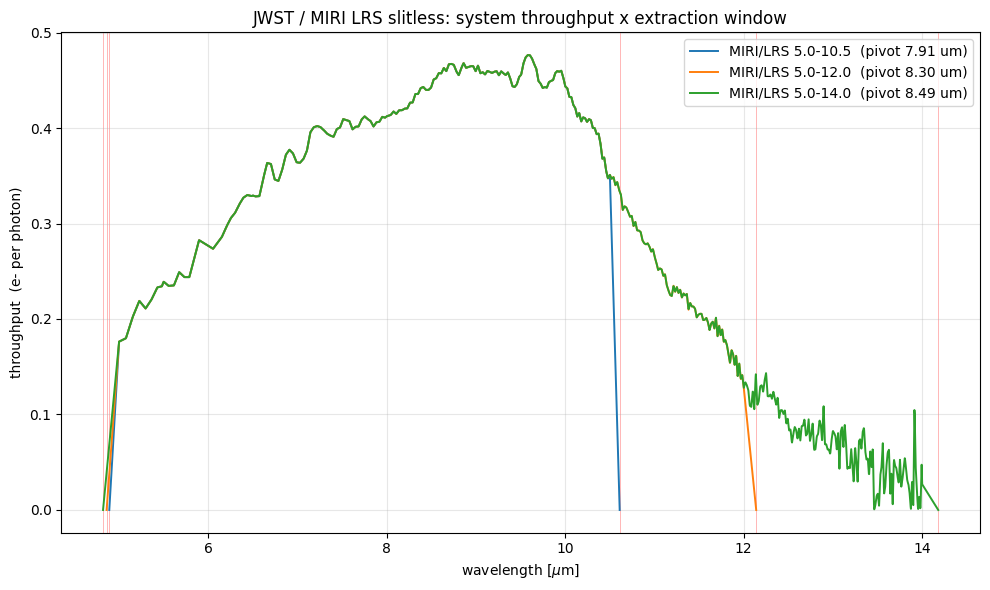

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for n, d in filters.items():
    ax.plot(d["w"] * um, d["T"], lw=1.4, label=f"{n}  (pivot {d['lpiv']*um:.2f} um)")
    ax.axvline(d["l1"] * um, color="red", lw=0.4, zorder=0, alpha=0.5)
    ax.axvline(d["l2"] * um, color="red", lw=0.4, zorder=0, alpha=0.5)
ax.set_xlabel(r"wavelength [$\mu$m]")
ax.set_ylabel("throughput  (e- per photon)")
ax.set_title("JWST / MIRI LRS slitless: system throughput x extraction window")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()